## Did dockless e-bikes eat London's Santander Cycles?
Author: Iyaomere David (Max), MSc Big Data Technologies, UEL


Question: after controlling for weather and calendar effects, did docked
bike hires fall once dockless e-bikes spread from 2022?


## 1. setup
Imports and folder paths so every later cell reads and writes in one place.

In [1]:
pip install pandas openpyxl requests statsmodels matplotlib jupyter holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Download the TfL hires data
Fetch the London Datastore file once and cache it, so reruns work offline.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import holidays
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf


RAW = Path("../data/raw"); RAW.mkdir(parents=True, exist_ok=True)
PROC = Path("../data/processed"); PROC.mkdir(parents=True, exist_ok=True)
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)

HIRES_URL = ("https://data.london.gov.uk/download/2r84d/"
             "ac29363e-e0cb-47cc-a97a-e216d900a6b0/"
             "tfl-daily-cycle-hires-sep26-update.xlsx")
hires_path = RAW / "tfl-daily-cycle-hires.xlsx"

In [3]:
if not hires_path.exists():
    r = requests.get(HIRES_URL, timeout=60)
    r.raise_for_status()
    hires_path.write_bytes(r.content)
print(pd.ExcelFile(hires_path).sheet_names)

['Metadata', 'Data']


## 3. Load daily hires
The workbook mixes daily, monthly and yearly figures, so this loader finds
the longest valid date-and-count column pair instead of hard-coding it.



In [4]:
def load_daily_hires(path):
    best=None
    for sheet in pd.ExcelFile(path).sheet_names:
        df=pd.read_excel(path, sheet_name=sheet)
        for i in range(df.shape[1]-1):
            d= pd.to_datetime(df.iloc[:,i], errors="coerce")
            n= pd.to_numeric(df.iloc[:,i+1], errors="coerce")
            ok=d.between("2010-01-01", "2024-12-31") & n.notna()
            if best is None or ok.sum() > best[0]:
                best=(ok.sum(), sheet, df.columns[1],pd.DataFrame({"date":d[ok].dt.normalize(), "hires":n[ok].astype(int)}))
    count, sheet, col, out = best
    print(f"Using sheet {sheet} and column {col} with {count} daily rows")
    return (out.drop_duplicates("date").sort_values("date").reset_index(drop=True))
hires = load_daily_hires(hires_path)
hires.head()

C:\Users\david\AppData\Local\Temp\ipykernel_22784\4173037984.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d= pd.to_datetime(df.iloc[:,i], errors="coerce")


Using sheet Data and column Unnamed: 1 with 5269 daily rows


C:\Users\david\AppData\Local\Temp\ipykernel_22784\4173037984.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d= pd.to_datetime(df.iloc[:,i], errors="coerce")
C:\Users\david\AppData\Local\Temp\ipykernel_22784\4173037984.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d= pd.to_datetime(df.iloc[:,i], errors="coerce")
C:\Users\david\AppData\Local\Temp\ipykernel_22784\4173037984.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d= pd.to_datetime(df.iloc[:,i], errors="coerce")
C:\Users\david\AppData\Local\Temp\ipykernel_22784\4173037984.py:6: UserWarning: Could not infe

,date,hires
0,2010-07-30,6897
1,2010-07-31,5564
2,2010-08-01,4303
3,2010-08-02,6642
4,2010-08-03,7966


## 4. Sanity checks
Confirm the date range, missing days and non-negative counts before trusting any result.

In [5]:
full = pd.date_range(hires.date.min(), hires.date.max(), freq="D")
missing= full.difference(hires.date)
print("Range:", hires.date.min().date(), "to", hires.date.max().date())
print("Missing dates: ", len(missing), list(missing[:10]))
print("Zero or negative days:", (hires.hires <= 0).sum())
print(hires.hires.describe())

assert hires.date.min() <= pd.Timestamp("2010-08-01")
assert (hires. hires >= 0).all()


Range: 2010-07-30 to 2024-12-31
Missing dates:  0 []
Zero or negative days: 2
count     5269.000000
mean     26325.037958
std       9497.831413
min          0.000000
25%      19746.000000
50%      26070.000000
75%      32745.000000
max      73094.000000
Name: hires, dtype: float64


## 5. Daily London weather
Pull temperature, rain and wind from Open-Meteo, because weather is the
main confounder in bike demand.

In [6]:
end = min(hires.date.max(), pd.Timestamp.today()- pd.Timedelta(days=10))
params ={
    "latitude": 51.5072,
    "longitude": -0.1276,
    "start_date": "2010-07-30",
    "end_date": end.strftime("%Y-%m-%d"),
    "daily":"temperature_2m_max,temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
    "timezone":"Europe/London",
}
r= requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
r.raise_for_status()
w= pd.DataFrame(r.json()["daily"]).rename(columns={
    "time": "date", "temperature_2m_max": "temp_max",
    "temperature_2m_mean": "temp_mean", "precipitation_sum": "rain_mm",
    "wind_speed_10m_max": "wind_max"})
w["date"]= pd.to_datetime(w["date"])
w.to_csv(RAW / "weather_london_daily.csv", index=False)
w.describe()

,date,temp_max,temp_mean,rain_mm,wind_max
count,5269,5269.000000,5269.000000,5269.000000,5269.000000
mean,2017-10-15 00:00:00,14.759347,11.119453,1.948434,21.302202
min,2010-07-30 00:00:00,-1.500000,-6.400000,0.000000,3.500000
25%,2014-03-08 00:00:00,10.200000,7.100000,0.000000,15.400000
50%,2017-10-15 00:00:00,14.500000,11.100000,0.300000,20.200000
75%,2021-05-24 00:00:00,19.300000,15.500000,2.300000,26.100000
max,2024-12-31 00:00:00,38.000000,29.100000,51.600000,68.000000
std,NaN,6.122127,5.498276,3.714191,8.017564


## 6. Merge and feature engineering
Join hires to weather and add calendar features (weekday, month, bank
holidays) plus the three periods: baseline, covid and e-bike era.

In [7]:
df = hires.merge(w, on="date", how="inner")

uk_hols = holidays.UK(subdiv="ENG", years=range(2010, 2027))
df["dow"] = df.date.dt.day_name()
df["is_weekend"] = df.date.dt.dayofweek >= 5
df["month"] = df.date.dt.month
df["year"] = df.date.dt.year
df["bank_holiday"] = df.date.dt.date.map(lambda d: d in uk_hols)
df["wet_day"] = df.rain_mm >= 1.0
df["heavy_rain"] = df.rain_mm >= 10.0
df["log_hires"] = np.log(df.hires.clip(lower=1))

# Periods for the headline question
def period(d):
    if d < pd.Timestamp("2020-03-23"):
        return "baseline"      # pre-pandemic
    if d < pd.Timestamp("2022-01-01"):
        return "covid"         # lockdowns + 2021 boom
    return "ebike_era"         # dockless e-bike growth
df["period"] = df.date.map(period)

df.to_csv(PROC / "daily.csv", index=False)
print(df.shape)
df.groupby("period").hires.agg(["count", "mean", "median"]).round(0)

(5269, 15)


,count,mean,median
period,,,
baseline,3524,25635.0,25556.0
covid,649,30142.0,30787.0
ebike_era,1096,26282.0,25700.0


## 7. Long-run trend
A 365-day rolling mean removes seasonality so the multi-year shape is visible.



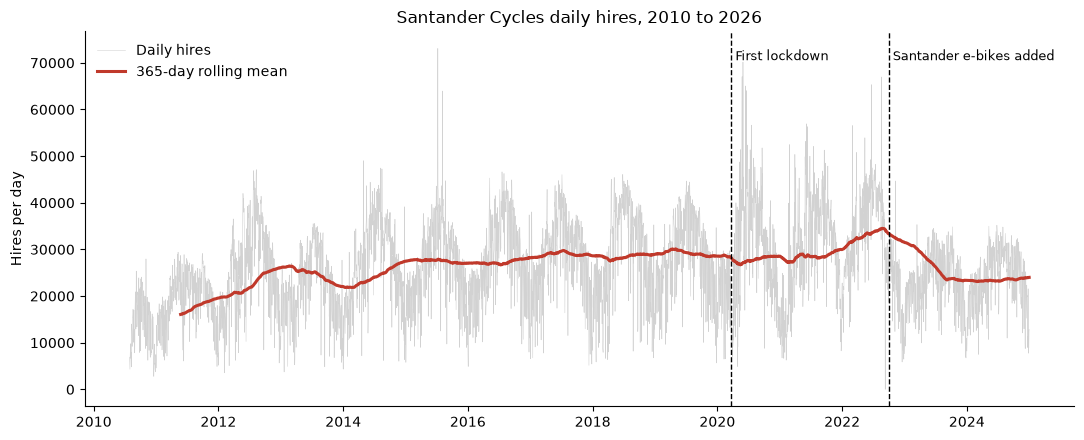

In [8]:
df = pd.read_csv(PROC / "daily.csv", parse_dates=["date"])

s = df.set_index("date").hires
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(s.index, s, lw=0.4, alpha=0.35, color="grey", label="Daily hires")
ax.plot(s.index, s.rolling(365, min_periods=300).mean(), lw=2.2,
        color="#c0392b", label="365-day rolling mean")
for x, lab in [("2020-03-23", "First lockdown"), ("2022-10-01", "Santander e-bikes added")]:
    ax.axvline(pd.Timestamp(x), ls="--", lw=1, color="black")
    ax.text(pd.Timestamp(x), ax.get_ylim()[1] * 0.95, " " + lab, fontsize=9, va="top")
ax.set_title("Santander Cycles daily hires, 2010 to 2026")
ax.set_ylabel("Hires per day")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "01_long_run_trend.png", dpi=200)

## 8. How weather drives demand
Temperature has the strongest link to hires, which is why raw year-on-year
comparisons can mislead.

           hires  temp_mean  rain_mm  wind_max
hires       1.00       0.60    -0.29     -0.26
temp_mean   0.60       1.00     0.03     -0.04
rain_mm    -0.29       0.03     1.00      0.27
wind_max   -0.26      -0.04     0.27      1.00


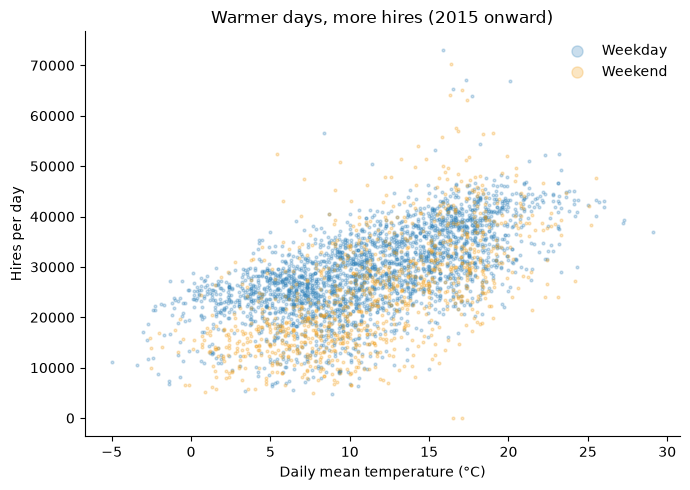

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for wk, colour, lab in [(False, "#2c7fb8", "Weekday"), (True, "#f39c12", "Weekend")]:
    sub = df[(df.is_weekend == wk) & (df.date >= "2015-01-01")]
    ax.scatter(sub.temp_mean, sub.hires, s=4, alpha=0.25, color=colour, label=lab)
ax.set_xlabel("Daily mean temperature (°C)")
ax.set_ylabel("Hires per day")
ax.set_title("Warmer days, more hires (2015 onward)")
ax.legend(frameon=False, markerscale=4)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "02_temperature_vs_hires.png", dpi=200)

print(df[["hires", "temp_mean", "rain_mm", "wind_max"]].corr().round(2))

## 9. Main model: weather-adjusted year effects
OLS on log hires (coefficients read as % changes) with HAC standard errors,
since daily residuals are autocorrelated. R² = [x].

In [10]:
sample = df[df.date >= "2015-01-01"].copy()
controls = ("temp_mean + I(temp_mean**2) + rain_mm + heavy_rain + wind_max"
            " + C(dow) + C(month) + bank_holiday")
m_year = smf.ols(f"log_hires ~ {controls} + C(year, Treatment(2019))",
                 data=sample).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
print(f"R-squared: {m_year.rsquared:.3f}")

ci = m_year.conf_int()
rows = []
for name, b in m_year.params.items():
    if name.startswith("C(year"):
        yr = int(name.split("[T.")[1].rstrip("]"))
        rows.append({"year": yr, "pct": np.expm1(b) * 100,
                     "lo": np.expm1(ci.loc[name, 0]) * 100,
                     "hi": np.expm1(ci.loc[name, 1]) * 100})
rows.append({"year": 2019, "pct": 0.0, "lo": 0.0, "hi": 0.0})
yr_fx = pd.DataFrame(rows).sort_values("year").reset_index(drop=True)
yr_fx.round(1)

R-squared: 0.457


,year,pct,lo,hi
0,2015,-7.3,-11.3,-3.1
1,2016,-5.0,-9.1,-0.8
2,2017,-2.1,-6.3,2.3
3,2018,-4.1,-8.4,0.4
4,2019,0.0,0.0,0.0
5,2020,-4.9,-13.3,4.3
6,2021,1.6,-6.8,10.6
7,2022,0.3,-12.6,15.1
8,2023,-18.4,-22.8,-13.7
9,2024,-16.5,-20.5,-12.4


## 10. Headline chart
Each bar shows a year's hires relative to 2019 after removing weather and
calendar effects.

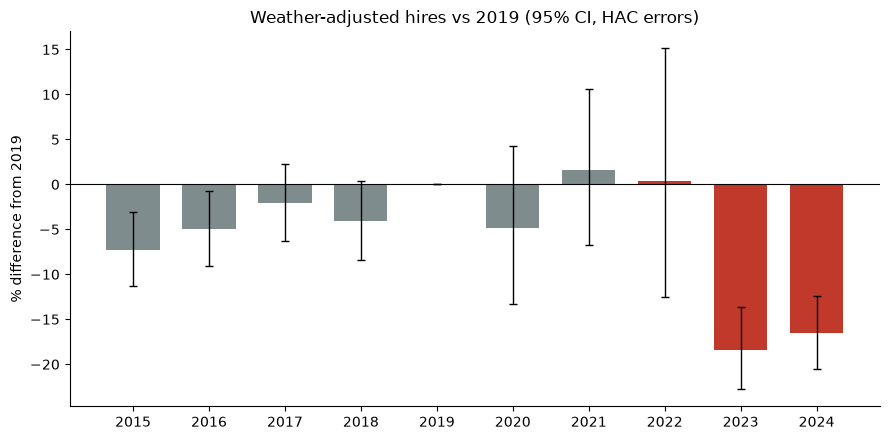

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = ["#c0392b" if y >= 2022 else "#7f8c8d" for y in yr_fx.year]
ax.bar(yr_fx.year, yr_fx.pct, color=colours, width=0.7)
ax.errorbar(yr_fx.year, yr_fx.pct,
            yerr=[yr_fx.pct - yr_fx.lo, yr_fx.hi - yr_fx.pct],
            fmt="none", ecolor="black", lw=1, capsize=3)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Weather-adjusted hires vs 2019 (95% CI, HAC errors)")
ax.set_ylabel("% difference from 2019")
ax.set_xticks(yr_fx.year)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "03_weather_adjusted_year_effects.png", dpi=200)

## 11. Robustness: does the cut-off date matter?
Re-estimate the e-bike era effect with three start dates. Result: [range].

In [12]:
def period_effect(data, cutoff):
    d = data.copy()
    d["era"] = np.select(
        [d.date < "2020-03-23", d.date < cutoff], ["baseline", "covid"], "ebike_era")
    m = smf.ols(f"log_hires ~ {controls} + C(era, Treatment('baseline'))",
                data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    key = "C(era, Treatment('baseline'))[T.ebike_era]"
    lo, hi = m.conf_int().loc[key]
    return {"cutoff": cutoff, "effect_pct": np.expm1(m.params[key]) * 100,
            "lo": np.expm1(lo) * 100, "hi": np.expm1(hi) * 100,
            "p_value": m.pvalues[key]}

robust = pd.DataFrame([period_effect(sample, c)
                       for c in ["2022-01-01", "2022-10-01", "2023-01-01"]])
robust.round(3)

,cutoff,effect_pct,lo,hi,p_value
0,2022-01-01,-8.674,-13.574,-3.497,0.001
1,2022-10-01,-13.840,-16.682,-10.900,0.000
2,2023-01-01,-14.391,-17.181,-11.507,0.000


## 12. Counterfactual gap
Train on 2016-19 only, then predict 2022+ using the real weather. The gap
is demand the old pattern cannot explain: [x]%.

2022+ overall: actual is -8.9% vs weather-adjusted 2016-19 expectation


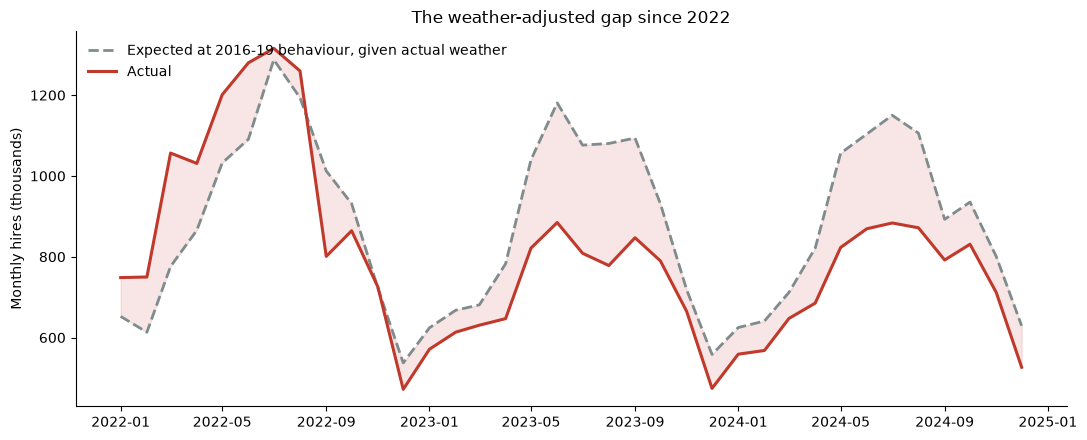

In [13]:
train = df[(df.date >= "2016-01-01") & (df.date < "2020-01-01")]
m_cf = smf.ols(f"log_hires ~ {controls}", data=train).fit()
smear = np.exp(m_cf.resid).mean()  # Duan smearing estimator

test = df[df.date >= "2022-01-01"].copy()
test["expected"] = np.exp(m_cf.predict(test)) * smear
monthly = test.set_index("date")[["hires", "expected"]].resample("MS").sum()
monthly["gap_pct"] = (monthly.hires / monthly.expected - 1) * 100
print(f"2022+ overall: actual is {monthly.hires.sum() / monthly.expected.sum() - 1:+.1%}"
      " vs weather-adjusted 2016-19 expectation")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly.expected / 1e3, color="#7f8c8d", lw=2,
        ls="--", label="Expected at 2016-19 behaviour, given actual weather")
ax.plot(monthly.index, monthly.hires / 1e3, color="#c0392b", lw=2.2, label="Actual")
ax.fill_between(monthly.index, monthly.hires / 1e3, monthly.expected / 1e3,
                color="#c0392b", alpha=0.12)
ax.set_title("The weather-adjusted gap since 2022")
ax.set_ylabel("Monthly hires (thousands)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "04_counterfactual_gap.png", dpi=200)

## 13. Diagnostics
Residual checks and the biggest misses, to see what the model leaves out
(strikes, snow).

Durbin-Watson: 0.98


,date,hires,temp_mean,rain_mm
4425,2022-09-10,0,16.5,0.8
4426,2022-09-11,0,17.1,0.0
5169,2024-09-23,24471,15.7,51.6
3560,2020-04-28,4872,8.9,13.6
3531,2020-03-30,7006,5.3,0.6
2340,2016-12-25,37401,10.4,0.0
3533,2020-04-01,9194,4.2,0.0
3534,2020-04-02,9898,8.0,0.0
3538,2020-04-06,10565,12.8,0.1
4534,2022-12-28,6461,10.5,4.0


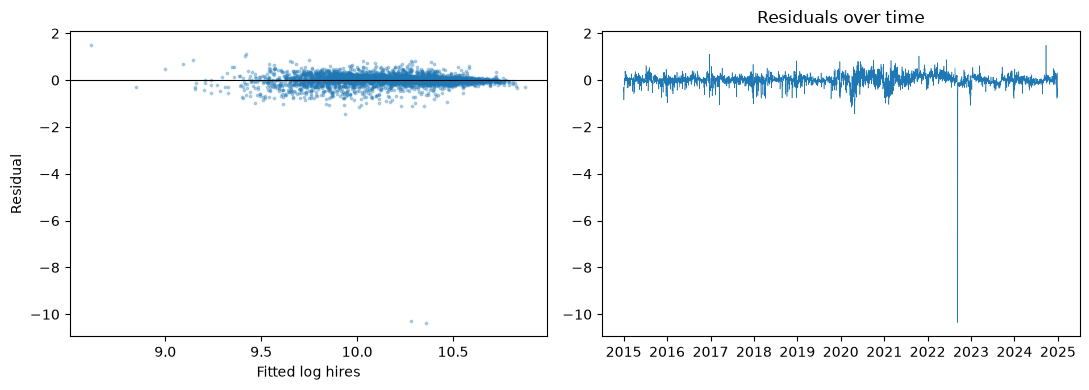

In [14]:
from statsmodels.stats.stattools import durbin_watson
print(f"Durbin-Watson: {durbin_watson(m_year.resid):.2f}")  # near 2 is good

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(m_year.fittedvalues, m_year.resid, s=3, alpha=0.3)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlabel("Fitted log hires"); axes[0].set_ylabel("Residual")
axes[1].plot(sample.date, m_year.resid, lw=0.4)
axes[1].set_title("Residuals over time")
fig.tight_layout(); fig.savefig(FIG / "05_diagnostics.png", dpi=150)

# The biggest misses are usually tube strikes (spikes) or snow days (drops)
sample.assign(resid=m_year.resid).reindex(
    m_year.resid.abs().nlargest(10).index)[["date", "hires", "temp_mean", "rain_mm"]]